# Advanced Data Mining — Deliverable 1
## Data Collection, Cleaning, and Exploration

**Dataset:** Breast Cancer Wisconsin (Diagnostic), originally from the UCI Machine Learning Repository, accessed through scikit-learn's built-in copy. The source dataset includes **569 observations and 30 numerical predictors**. This concise analysis retains **10 interpretable mean-measurement attributes** plus the diagnosis label (11 columns total). The diagnosis is an existing dataset label, not a clinical prediction made in this notebook.

Original dataset: https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic  
Loading documentation: https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html

**Objective:** Audit data quality, inspect class distributions and continuous feature behavior, visualize correlations/outliers, and identify important preprocessing considerations for later deliverables. **No predictive model is trained in Deliverable 1.**

> **Ethics:** This is a retrospective teaching dataset. Group differences and exploratory associations are not clinical diagnostic rules or evidence of causal relationships.

**Expanded visual guide:** The notebook additionally creates a workflow diagram, predictor map, data-quality dashboard, IQR screening chart, and class-wise mean comparison (10 visual files total).

In [1]:
# 1. Import the analysis tools. No internet connection is required.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.datasets import load_breast_cancer

sns.set_theme(style="whitegrid", font_scale=1.0)
OUT = Path("figures")
DATA = Path("data")
OUT.mkdir(exist_ok=True)
DATA.mkdir(exist_ok=True)
pd.set_option("display.max_columns", 20)
print("Pandas version:", pd.__version__)

Pandas version: 2.2.3


In [ ]:
# 1a. Reproducible workflow overview (diagram, no model training).
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
fig, ax = plt.subplots(figsize=(13, 3.15))
ax.set_xlim(0, 13); ax.set_ylim(0, 3.15); ax.axis("off")
stages = [("1  LOAD", "569 records\n30 original predictors"),
          ("2  SELECT", "10 mean measurements\n+ diagnosis label"),
          ("3  AUDIT", "Missing • duplicates\nvalidity • IQR flags"),
          ("4  EXPLORE", "Distributions • groups\ncorrelations • outliers")]
xs = [0.3, 3.55, 6.8, 10.05]
for i, ((title, detail), x) in enumerate(zip(stages, xs)):
    patch = FancyBboxPatch((x, 1.15), 2.62, 1.30,
                           boxstyle="round,pad=0.12,rounding_size=.18",
                           facecolor="#EEF5F7" if i % 2 == 0 else "#F7F2EE",
                           edgecolor="#267B91" if i % 2 == 0 else "#C76F61", linewidth=1.8)
    ax.add_patch(patch)
    ax.text(x + 1.31, 2.03, title, ha="center", va="center", color="#21465E", fontsize=16, weight="bold")
    ax.text(x + 1.31, 1.54, detail, ha="center", va="center", color="#304653", fontsize=11.4, linespacing=1.5)
    if i < 3:
        ax.add_patch(FancyArrowPatch((x+2.76, 1.81), (xs[i+1]-.12, 1.81),
                                    arrowstyle="-|>", mutation_scale=18, color="#566772", lw=2))
ax.text(6.5, .57, "Deliverable 1: establish a reproducible data foundation before predictive modeling",
        ha="center", color="#21465E", fontsize=13, style="italic")
fig.tight_layout(pad=.2)
fig.savefig(OUT / "06_analysis_workflow.png", dpi=180, bbox_inches="tight")
plt.show()

### 1. Data acquisition and feature selection
The original UCI collection contains 30 measurements of cell nuclei, summarized as mean, standard error, and worst values. I use the ten **mean** features to meet the assignment's attribute requirement while keeping interpretation concise. The class mapping is verified from the data provider: `0 = malignant`, `1 = benign`.

In [2]:
# 2. Access a reproducible copy of the real UCI dataset bundled in scikit-learn.
source = load_breast_cancer(as_frame=True)
features = [
    "mean radius", "mean texture", "mean perimeter", "mean area",
    "mean smoothness", "mean compactness", "mean concavity",
    "mean concave points", "mean symmetry", "mean fractal dimension",
]
df = source.data.loc[:, features].copy()
df["diagnosis"] = source.target.map({0: "malignant", 1: "benign"})
assert df.shape == (569, 11)
assert set(df["diagnosis"]) == {"benign", "malignant"}
print("Shape:", df.shape)
display(df.head())
print("Target names (original 0, 1 order):", source.target_names)
print("Column types:\n", df.dtypes.to_string())

Shape: (569, 11)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,malignant


Target names (original 0, 1 order): ['malignant' 'benign']
Column types:
 mean radius               float64
mean texture              float64
mean perimeter            float64
mean area                 float64
mean smoothness           float64
mean compactness          float64
mean concavity            float64
mean concave points       float64
mean symmetry             float64
mean fractal dimension    float64
diagnosis                  object


In [ ]:
# 2a. Diagram of the ten predictors (the outcome is kept separate).
from matplotlib.patches import FancyBboxPatch
groups = [("SIZE", "Mean radius\nMean perimeter\nMean area"),
          ("TEXTURE & SURFACE", "Mean texture\nMean smoothness\nMean compactness"),
          ("SHAPE & COMPLEXITY", "Mean concavity\nMean concave points\nMean symmetry\nMean fractal dimension")]
fig, ax = plt.subplots(figsize=(12.5, 4.25))
ax.axis("off"); ax.set_xlim(0, 12.5); ax.set_ylim(0, 4.25)
for i, (name, content) in enumerate(groups):
    x = .4 + i * 4.1
    patch = FancyBboxPatch((x, .95), 3.7, 2.78, boxstyle="round,pad=.09,rounding_size=.15",
                           facecolor=["#EAF4F6", "#F9F1EB", "#EFF4F1"][i],
                           edgecolor=["#267B91", "#C76F61", "#699784"][i], linewidth=1.7)
    ax.add_patch(patch)
    ax.text(x+1.85, 3.33, name, ha="center", va="center", color="#21465E", fontsize=14, weight="bold")
    ax.plot([x+.35, x+3.35], [3.09, 3.09], color="#A1ABB2", lw=1)
    ax.text(x+1.85, 2.12, content, ha="center", va="center", fontsize=13, linespacing=1.65, color="#233C4A")
ax.text(6.25, .37, "Outcome label (separate from predictors):  diagnosis = benign or malignant",
        ha="center", color="#21465E", fontsize=12.5, weight="bold")
fig.tight_layout(pad=.3)
fig.savefig(OUT / "07_selected_feature_structure.png", dpi=180, bbox_inches="tight")
plt.show()

In [3]:
# 3. Check structure, completeness, descriptive statistics, and repeated records.
print("Rows/columns:", df.shape)
print("Missing values by column:\n", df.isna().sum().to_string())
print("Duplicate complete rows:", int(df.duplicated().sum()))
print("Nonfinite numeric cells:", int((~np.isfinite(df[features].to_numpy())).sum()))
display(df[features].describe().T.round(3))
print("Diagnosis counts:\n", df["diagnosis"].value_counts().to_string())

Rows/columns: (569, 11)
Missing values by column:
 mean radius               0
mean texture              0
mean perimeter            0
mean area                 0
mean smoothness           0
mean compactness          0
mean concavity            0
mean concave points       0
mean symmetry             0
mean fractal dimension    0
diagnosis                 0
Duplicate complete rows: 0
Nonfinite numeric cells: 0


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127,3.524,6.981,11.700,13.370,15.780,28.110
mean texture,569.0,19.290,4.301,9.710,16.170,18.840,21.800,39.280
mean perimeter,569.0,91.969,24.299,43.790,75.170,86.240,104.100,188.500
mean area,569.0,654.889,351.914,143.500,420.300,551.100,782.700,2501.000
mean smoothness,569.0,0.096,0.014,0.053,0.086,0.096,0.105,0.163
mean compactness,569.0,0.104,0.053,0.019,0.065,0.093,0.130,0.345
mean concavity,569.0,0.089,0.080,0.000,0.030,0.062,0.131,0.427
mean concave points,569.0,0.049,0.039,0.000,0.020,0.034,0.074,0.201
mean symmetry,569.0,0.181,0.027,0.106,0.162,0.179,0.196,0.304
mean fractal dimension,569.0,0.063,0.007,0.050,0.058,0.062,0.066,0.097


Diagnosis counts:
 diagnosis
benign       357
malignant    212


### 2. Data cleaning and quality assurance
All selected columns are numeric and the diagnosis labels are valid. The original data have no missing values or complete-row duplicates. The following pipeline nevertheless **checks** for invalid negative measurements, performs median imputation **only if needed**, and removes **only true full-row duplicates**. It does not remove IQR outliers automatically: extreme biological observations should not be mislabeled as measurement errors without domain evidence. Any future transformation parameters must be learned **within the training folds**, not on the entire dataset.

In [4]:
# 4. Run a transparent, conditional cleaning pipeline.
cleaned = df.copy()
for col in features:
    cleaned[col] = pd.to_numeric(cleaned[col], errors="coerce")
    # The ten cell-nucleus measurements cannot be negative. Zero can be valid
    # for some shape measures (e.g., concavity), so we do not flag zero.
    cleaned.loc[cleaned[col] < 0, col] = np.nan
    if cleaned[col].isna().any():
        cleaned[col] = cleaned[col].fillna(cleaned[col].median())

before_dedup = len(cleaned)
cleaned = cleaned.drop_duplicates().reset_index(drop=True)
print("Rows removed as exact duplicates:", before_dedup - len(cleaned))
print("Missing values after cleaning:", int(cleaned.isna().sum().sum()))
print("Final data shape:", cleaned.shape)
assert cleaned.shape == (569, 11)
cleaned.to_csv(DATA / "wdbc_cleaned.csv", index=False)
print("Saved", DATA / "wdbc_cleaned.csv")

Rows removed as exact duplicates: 0
Missing values after cleaning: 0
Final data shape: (569, 11)
Saved data/wdbc_cleaned.csv


In [ ]:
# 4a. Display verified data-quality checks in a figure.
quality_counts = [int(df.isna().sum().sum()), int(df.duplicated().sum()),
                  int((df[features] < 0).sum().sum()), len(cleaned)]
quality_labels = ["Missing cells", "Duplicate rows", "Negative measurements", "Records retained"]
fig, ax = plt.subplots(figsize=(11.5, 3))
ax.set_xlim(0, 11.5); ax.set_ylim(0, 3); ax.axis("off")
for i, (label, value) in enumerate(zip(quality_labels, quality_counts)):
    x = .2 + i * 2.88
    patch = FancyBboxPatch((x, .34), 2.63, 2.32, boxstyle="round,pad=.08,rounding_size=.17",
                           facecolor="#EEF5F7" if i < 3 else "#E7F2EA", edgecolor="#9CB2BD", lw=1.3)
    ax.add_patch(patch)
    ax.text(x+1.32, 1.73, str(value), ha="center", va="center", fontsize=27, weight="bold",
            color="#267B91" if i < 3 else "#397C56")
    ax.text(x+1.32, .91, label, ha="center", va="center", fontsize=11.5, color="#21465E")
fig.tight_layout(pad=.2)
fig.savefig(OUT / "08_cleaning_audit_dashboard.png", dpi=180, bbox_inches="tight")
plt.show()

In [5]:
# 5. Quantify potential outliers with the 1.5 x IQR rule (screen, not delete).
flags = []
for col in features:
    q1, q3 = cleaned[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    count = int(((cleaned[col] < lower) | (cleaned[col] > upper)).sum())
    flags.append({"feature": col, "IQR_flagged_rows": count,
                  "lower_fence": round(lower, 4), "upper_fence": round(upper, 4)})
outlier_summary = pd.DataFrame(flags).sort_values("IQR_flagged_rows", ascending=False)
display(outlier_summary)
print("Area flagged:", int(outlier_summary.set_index('feature').loc['mean area','IQR_flagged_rows']))

,feature,IQR_flagged_rows,lower_fence,upper_fence
3,mean area,25,-123.3000,1326.3000
6,mean concavity,18,-0.1222,0.2824
5,mean compactness,16,-0.0333,0.2286
8,mean symmetry,15,0.1112,0.2464
9,mean fractal dimension,15,0.0451,0.0787
0,mean radius,14,5.5800,21.9000
2,mean perimeter,13,31.7750,147.4950
7,mean concave points,10,-0.0602,0.1545
1,mean texture,7,7.7250,30.2450
4,mean smoothness,6,0.0580,0.1337


Area flagged: 25


In [ ]:
# 5a. Compare IQR-flagged counts; no flagged observations are removed.
screen = outlier_summary.copy()
screen["short_label"] = screen["feature"].str.replace("mean ", "", regex=False).str.title()
screen = screen.sort_values("IQR_flagged_rows", ascending=False)
fig, ax = plt.subplots(figsize=(10, 5.4))
counts = screen["IQR_flagged_rows"].tolist()
labels = screen["short_label"].tolist()
bars = ax.barh(labels, counts, color=["#C76F61" if v in ("Area", "Radius") else "#267B91" for v in labels])
ax.invert_yaxis()
ax.set(title="1.5 × IQR screening by measurement", xlabel="Flagged rows (not deleted)", ylabel="Selected measurement")
ax.set_xlim(0, max(counts) + max(10, int(max(counts)*.16)))
for bar, n in zip(bars, counts):
    ax.text(n+.6, bar.get_y()+bar.get_height()/2, str(n), va="center", fontsize=10.3)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(OUT / "09_iqr_outlier_summary.png", dpi=170)
plt.show()

### 3. Exploratory data analysis
Each visualization has a descriptive title, labeled axes, and a consistent interpretation. Graphs are saved as PNG files for direct use in the written report or GitHub repository.

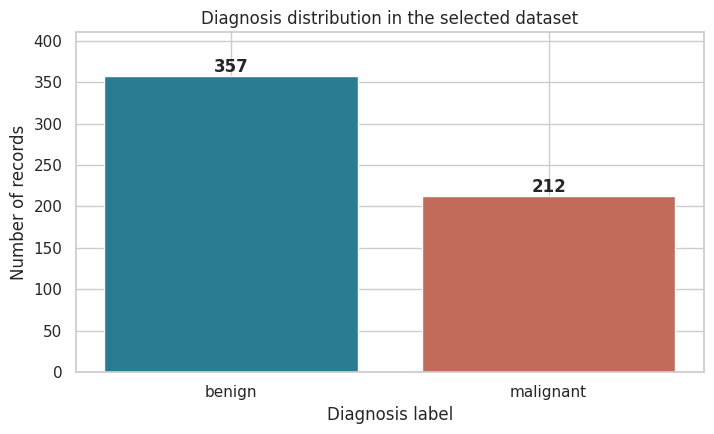

In [6]:
# 6. Class counts: an important consideration for accuracy and recall.
counts = cleaned["diagnosis"].value_counts().reindex(["benign", "malignant"])
fig, ax = plt.subplots(figsize=(7.3, 4.5))
bars = ax.bar(counts.index, counts.values, color=["#297C91", "#C36B5B"])
for bar, v in zip(bars, counts.values):
    ax.text(bar.get_x()+bar.get_width()/2, v+5, str(v), ha="center", fontweight="bold")
ax.set(title="Diagnosis distribution in the selected dataset",
       xlabel="Diagnosis label", ylabel="Number of records", ylim=(0, 410))
fig.tight_layout()
fig.savefig(OUT / "01_diagnosis_distribution.png", dpi=170)
plt.show()

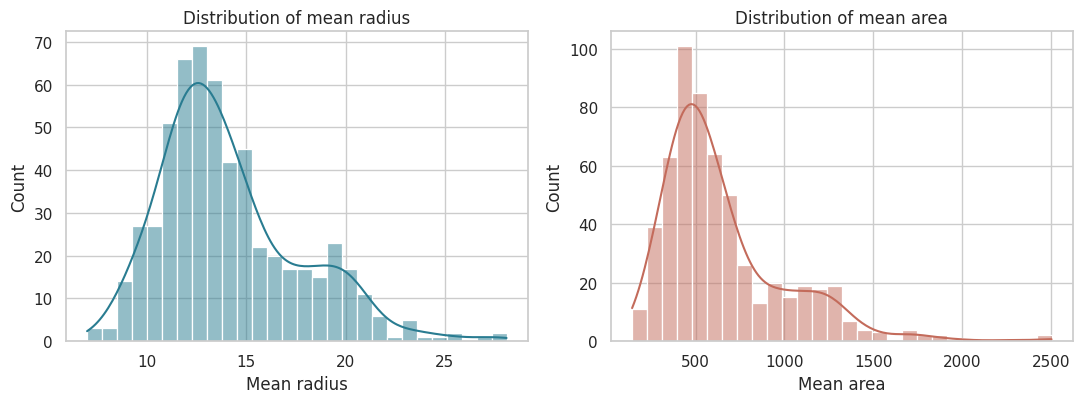

In [7]:
# 7. Distribution shapes can reveal skew and non-normality.
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
sns.histplot(cleaned["mean radius"], bins=28, kde=True, ax=axes[0], color="#297C91")
axes[0].set(title="Distribution of mean radius", xlabel="Mean radius", ylabel="Count")
sns.histplot(cleaned["mean area"], bins=28, kde=True, ax=axes[1], color="#C36B5B")
axes[1].set(title="Distribution of mean area", xlabel="Mean area", ylabel="Count")
fig.tight_layout()
fig.savefig(OUT / "02_radius_and_area_histograms.png", dpi=170)
plt.show()

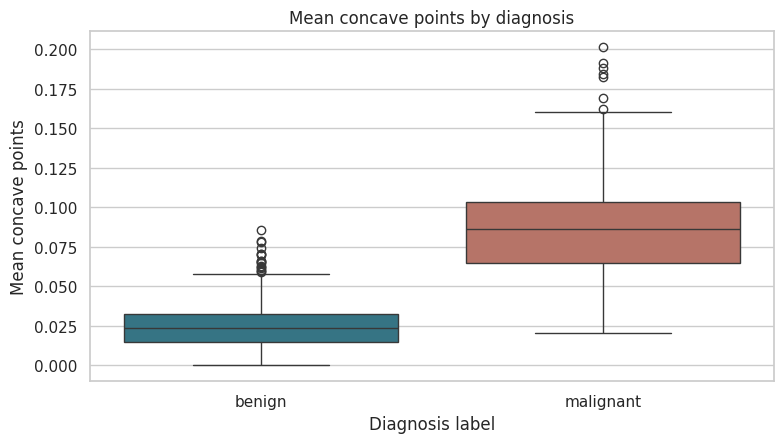

In [8]:
# 8. Compare the central tendency and spread of an informative morphology feature.
fig, ax = plt.subplots(figsize=(8, 4.6))
sns.boxplot(data=cleaned, x="diagnosis", y="mean concave points", order=["benign", "malignant"],
            hue="diagnosis", palette={"benign":"#297C91", "malignant":"#C36B5B"},
            legend=False, ax=ax)
ax.set(title="Mean concave points by diagnosis", xlabel="Diagnosis label",
       ylabel="Mean concave points")
fig.tight_layout()
fig.savefig(OUT / "03_concave_points_by_diagnosis.png", dpi=170)
plt.show()

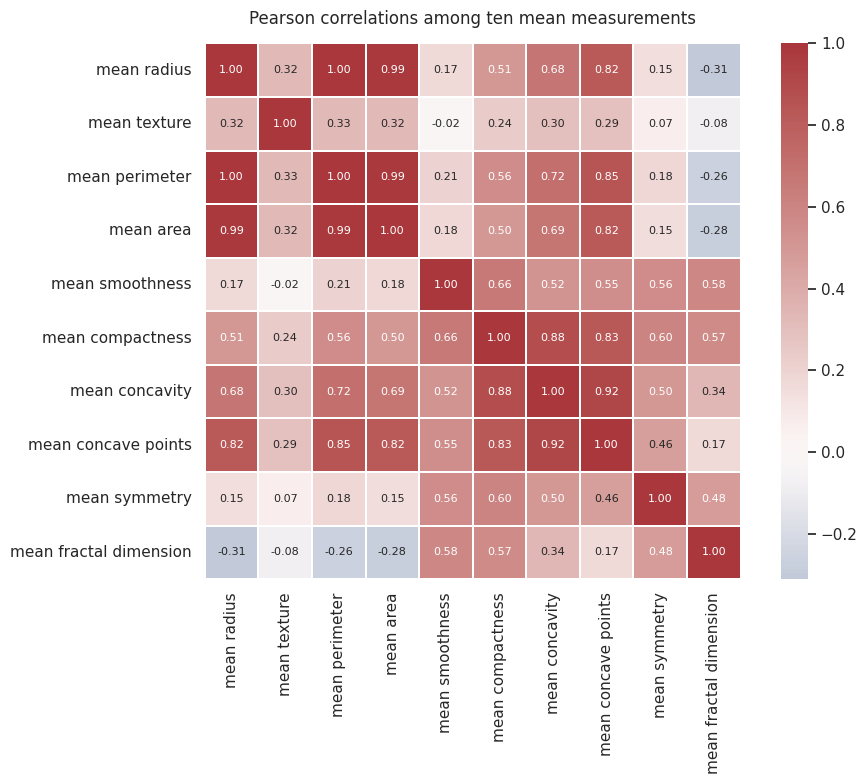

Correlation between mean radius and mean perimeter: 0.998


In [9]:
# 9. Explore redundancy and candidate feature-selection issues.
corr = cleaned[features].corr()
fig, ax = plt.subplots(figsize=(10.2, 8.0))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0,
            linewidths=.3, square=True, annot_kws={"size":8}, ax=ax)
ax.set_title("Pearson correlations among ten mean measurements", pad=14)
fig.tight_layout()
fig.savefig(OUT / "04_feature_correlation_heatmap.png", dpi=170)
plt.show()
print("Correlation between mean radius and mean perimeter:",
      round(corr.loc["mean radius", "mean perimeter"], 3))

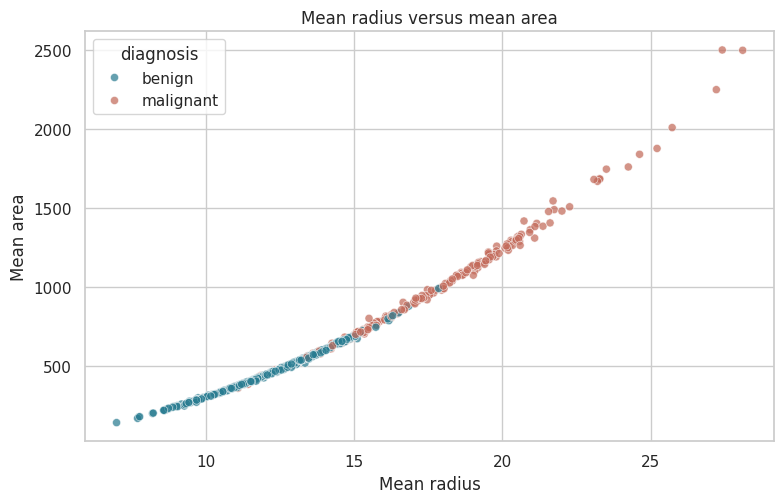

In [10]:
# 10. Compare two related measures, with class labels shown separately.
fig, ax = plt.subplots(figsize=(8, 5.2))
sns.scatterplot(data=cleaned, x="mean radius", y="mean area", hue="diagnosis",
                hue_order=["benign", "malignant"], alpha=.72, s=34,
                palette={"benign":"#297C91", "malignant":"#C36B5B"}, ax=ax)
ax.set(title="Mean radius versus mean area", xlabel="Mean radius", ylabel="Mean area")
fig.tight_layout()
fig.savefig(OUT / "05_radius_area_scatter.png", dpi=170)
plt.show()

In [11]:
# 11. Summarize class-level patterns using the underlying records.
key_features = ["mean radius", "mean area", "mean texture", "mean concave points"]
summary = cleaned.groupby("diagnosis")[key_features].mean().round(3)
print("Selected class-wise means:")
display(summary)
print("Class proportions (%)")
display((cleaned["diagnosis"].value_counts(normalize=True)*100).round(1))

Selected class-wise means:


,mean radius,mean area,mean texture,mean concave points
diagnosis,,,,
benign,12.147,462.790,17.915,0.026
malignant,17.463,978.376,21.605,0.088


Class proportions (%)


diagnosis
benign       62.7
malignant    37.3
Name: proportion, dtype: float64

In [ ]:
# 11a. Chart three class-wise means on their own scales (units differ across features).
fields = ["mean radius", "mean area", "mean concave points"]
means = cleaned.groupby("diagnosis")[fields].mean()
fig, axes = plt.subplots(1, 3, figsize=(12, 4.2))
for ax, col in zip(axes, fields):
    values = [means.loc["benign", col], means.loc["malignant", col]]
    bars = ax.bar(["Benign", "Malignant"], values, color=["#267B91", "#C76F61"], width=.66)
    ax.set_title(col.title(), fontsize=13, weight="bold")
    ax.set_ylim(0, max(values) * 1.25)
    for bar, v in zip(bars, values):
        value_text = f"{v:.3f}" if max(values) < 1 else f"{v:.1f}"
        ax.text(bar.get_x()+bar.get_width()/2, v + max(values)*.03, value_text,
                ha="center", fontsize=10.7, weight="bold")
    ax.set_ylabel("Group mean")
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Selected measurements by existing diagnosis label", fontsize=14, weight="bold", y=1.03)
fig.tight_layout()
fig.savefig(OUT / "10_classwise_feature_means.png", dpi=180, bbox_inches="tight")
plt.show()

### 4. Interpretation and next steps

- **Missingness and duplicates:** Neither occurs in the selected 569-row extract, so no values were invented and no rows were removed.
- **Class representation:** 357 benign vs. 212 malignant cases (~62.7% vs. ~37.3%). Later classification should use stratification and recall/F1/ROC-AUC alongside accuracy; any sampling is limited to the training data.
- **Feature relationships:** `mean radius` and `mean perimeter` are nearly redundant (Pearson *r* ≈ 0.998). Correlated features should be considered during feature selection and regularized modeling.
- **Potential outliers:** The IQR screen identifies unusually high/low values (e.g., 25 mean-area values). These are retained because an IQR flag is not proof of an error.
- **Group differences:** The malignant group has larger mean radius and mean concave points **in this dataset**. Descriptive separation does not establish causation, generalizability, or clinical usefulness.
- **Later stages:** For Deliverable 2, `mean area` could be a continuous regression outcome *if excluded from the predictor matrix*. For Deliverable 3, `diagnosis` is the classification outcome; clusters may use standardized features, and association rules may use discretized non-label characteristics. Data splitting must precede all fitted preprocessing to avoid leakage.

**Reproduction:** Run all cells from top to bottom. The `data/` and `figures/` folders are created automatically. This notebook performs only the first deliverable.